Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


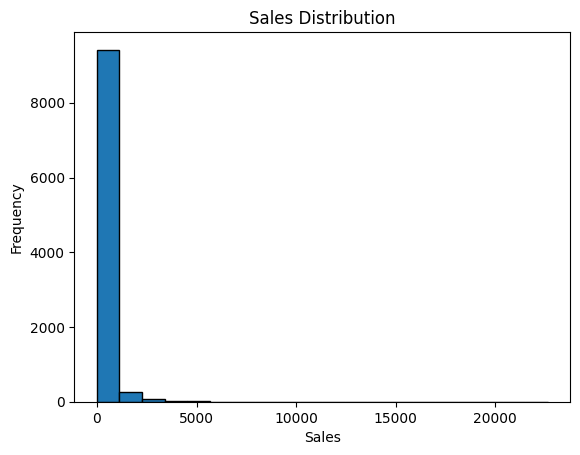

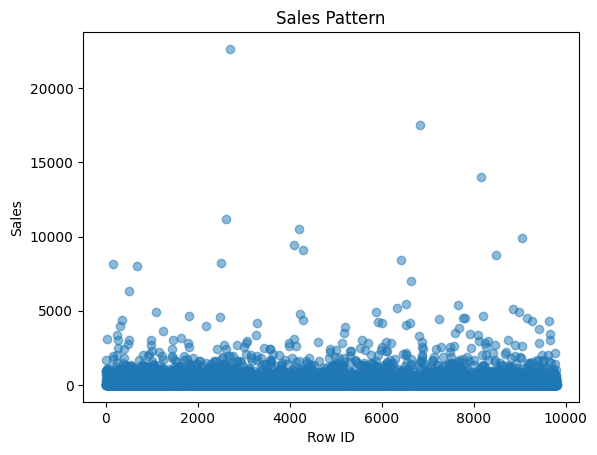

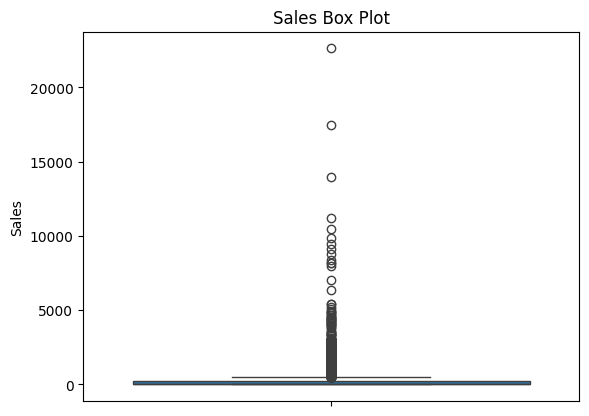

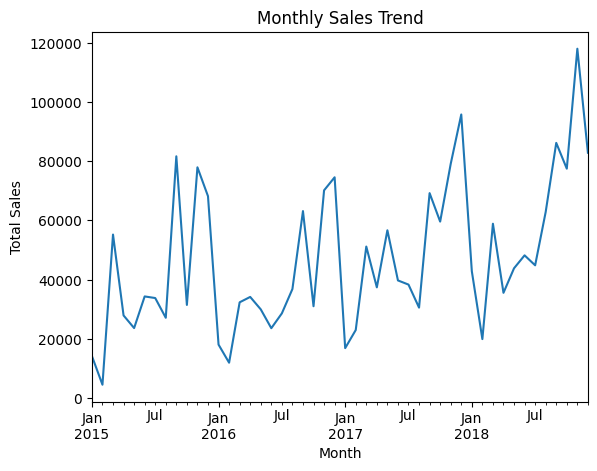

Correlation between Row ID and Sales: -0.0
Highest Sales Category: Technology
Highest Category Sales: 825856.11


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

# Mount Drive
drive.mount('/content/drive')

# Load dataset
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/PBA PRACTICAL FILE/superstore.csv')

# Preprocessing
df = df.dropna().drop_duplicates()
df['Order Date'] = pd.to_datetime(df['Order Date'], dayfirst=True)

# 1. Histogram - Sales Distribution
plt.hist(df['Sales'], bins=20, edgecolor='black')
plt.title('Sales Distribution')
plt.xlabel('Sales')
plt.ylabel('Frequency')
plt.show()

# 2. Scatter Plot - Sales Pattern
plt.scatter(df['Row ID'], df['Sales'], alpha=0.5)
plt.title('Sales Pattern')
plt.xlabel('Row ID')
plt.ylabel('Sales')
plt.show()

# 3. Box Plot - Sales
sns.boxplot(y=df['Sales'])
plt.title('Sales Box Plot')
plt.ylabel('Sales')
plt.show()

# 4. Sales Trend
monthly_sales = df.groupby(
    df['Order Date'].dt.to_period('M')
)['Sales'].sum()

monthly_sales.plot()
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.show()

# Correlation
correlation = df['Row ID'].corr(df['Sales'])
print("Correlation between Row ID and Sales:", round(correlation, 2))

# Business Insight
category_sales = df.groupby('Category')['Sales'].sum()
print("Highest Sales Category:", category_sales.idxmax())
print("Highest Category Sales:", round(category_sales.max(), 2))